# 국제시장권 | 쇼핑 밀집형

* 자료: 공개 가능한 저장 요약값
* 관측 단위: 시장 소재 행정동, 실제 방문·구매 미확인
* 공개 범위: OD·STAY 원자료 제외

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from plotting import (FIGS, HOUR, WEEK, STAY, PURPOSE, CASE_COMPARISONS, PURPOSE_FIGURES, TIME_FIGURES,
                      plot_case_comparison, plot_purpose, plot_time_weekday)
CASE = '국제시장권'


## 방문·체류 목적

,도착 OD,체류 STAY
귀가,16.1,26.9
업무,11.7,20.8
학업,0.1,0.1
쇼핑여가,40.7,27.6
기타,15.8,14.3
여행,15.7,10.4


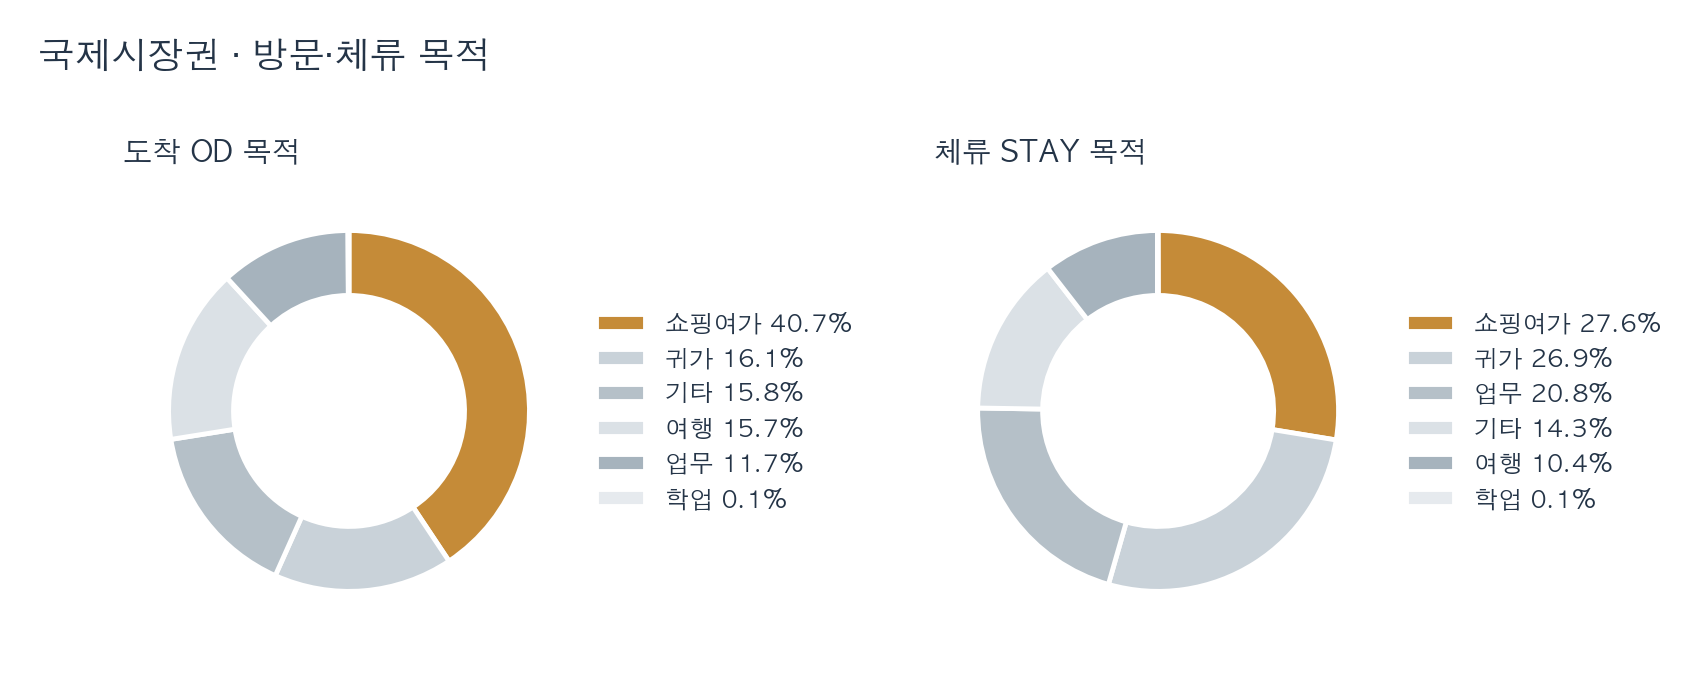

In [2]:
display((pd.DataFrame(PURPOSE[CASE]) * 100).round(1))
plot_purpose(CASE)
display(Image(filename=str(FIGS / PURPOSE_FIGURES[CASE][0])))

## 체류 구성

In [3]:
stay = STAY
selected = stay.loc[stay["case"].eq(CASE),
                    ["metric", "case_share", "national_market_row_mean", "scope"]].copy()
selected[["case_share", "national_market_row_mean"]] *= 100
display(selected.rename(columns={"case_share":"사례 (%)",
                                  "national_market_row_mean":"전국 시장 행 평균 (%)"}))

,metric,사례 (%),전국 시장 행 평균 (%),scope
2,쇼핑여가 목적 STAY,27.573561,3.727711,2023-09-01~2023-10-15 중 일반일 38일; 전목적 STAY 시간별 ...
3,쇼핑여가 목적 STAY 중 60대 이상,24.971399,17.700372,2023-09-01~2023-10-15 중 일반일 38일; 쇼핑여가 목적 STAY ...


## 거리·접근

* 그림: 비공개 시설·공간 입력으로 작성한 저장 결과
* 재생성: 비공개 입력 경로 지정 시 가능

비공개 시장 위치 입력이 없어 저장된 지도를 표시합니다.


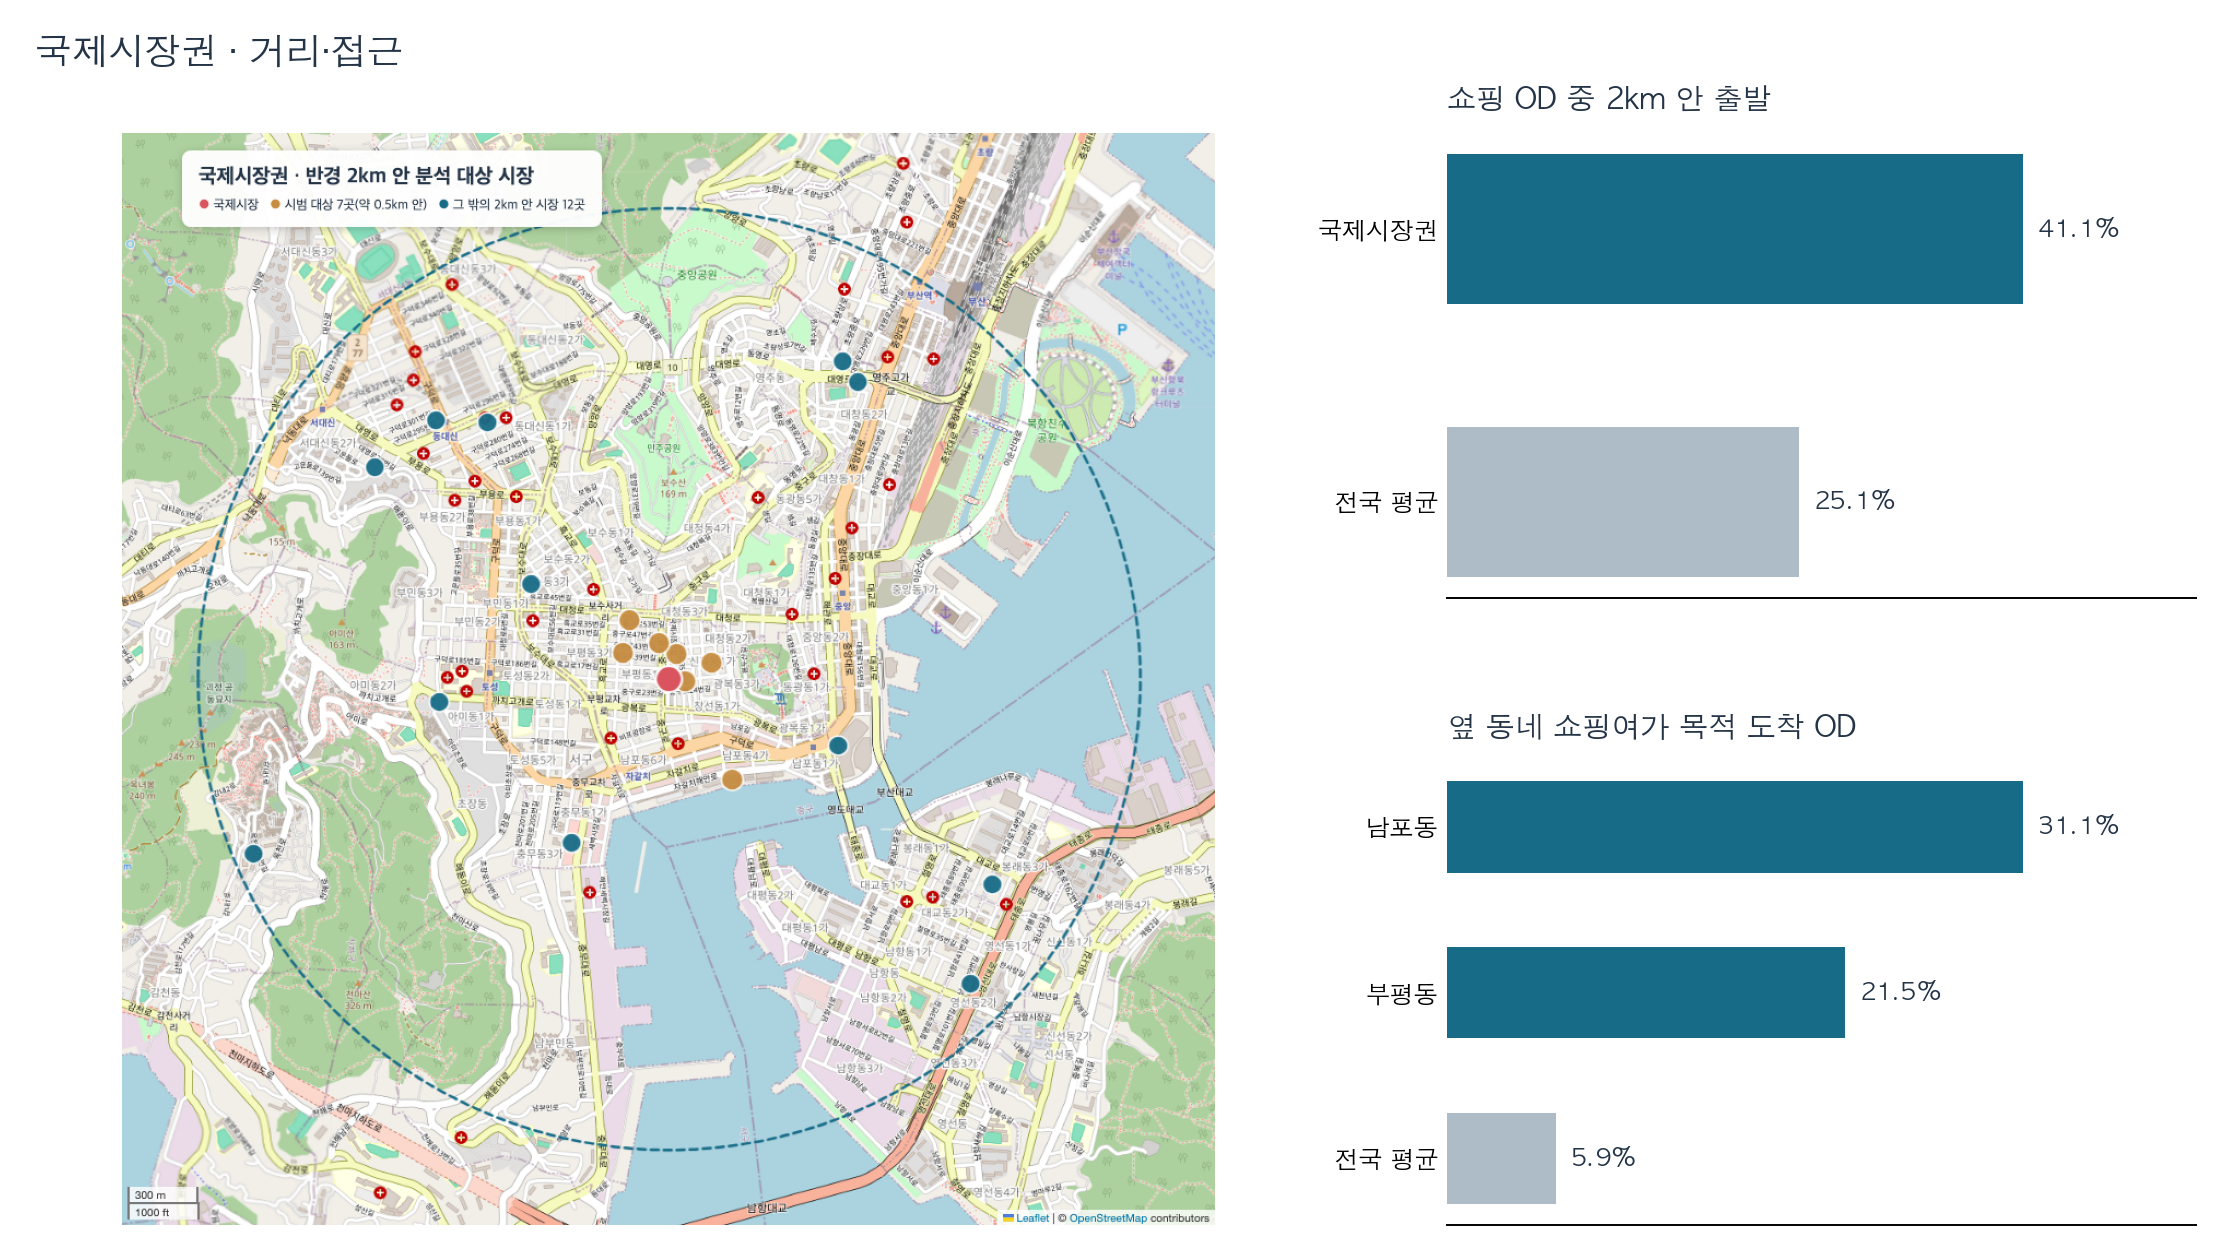

In [4]:
import os, tempfile
from plotting import international, render_map_png, plot_international_nearby
features_path = os.environ.get("BC_MARKET_FEATURES")
figure_path = Path("../figs") / "fig_v4_4b_international_nearby.png"
if features_path and Path(features_path).exists():
    features = pd.read_csv(features_path, dtype={"행정기관코드": str})
    with tempfile.TemporaryDirectory() as folder:
        map_html = international(features, Path(folder))
        map_png = Path(folder) / "map.png"
        render_map_png(map_html, map_png, 1000, 1000)
        plot_international_nearby(map_png)
    figure_path = FIGS / "fig_v4_4b_international_nearby.png"
else:
    print("비공개 시장 위치 입력이 없어 저장된 지도를 표시합니다.")
display(Image(filename=str(figure_path)))

## 제안

* 방안: 약 0.5km 안 8개 시장의 공동 지도·쿠폰과 동선 안내 시범 검토
* 상태: 시행·효과 미확인